# Resultater

In [7]:
import pandas as pd
import numpy as np
from sklearn.metrics import roc_curve, roc_auc_score, auc, precision_recall_curve
import plotly.express as px
import plotly.graph_objects as go
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

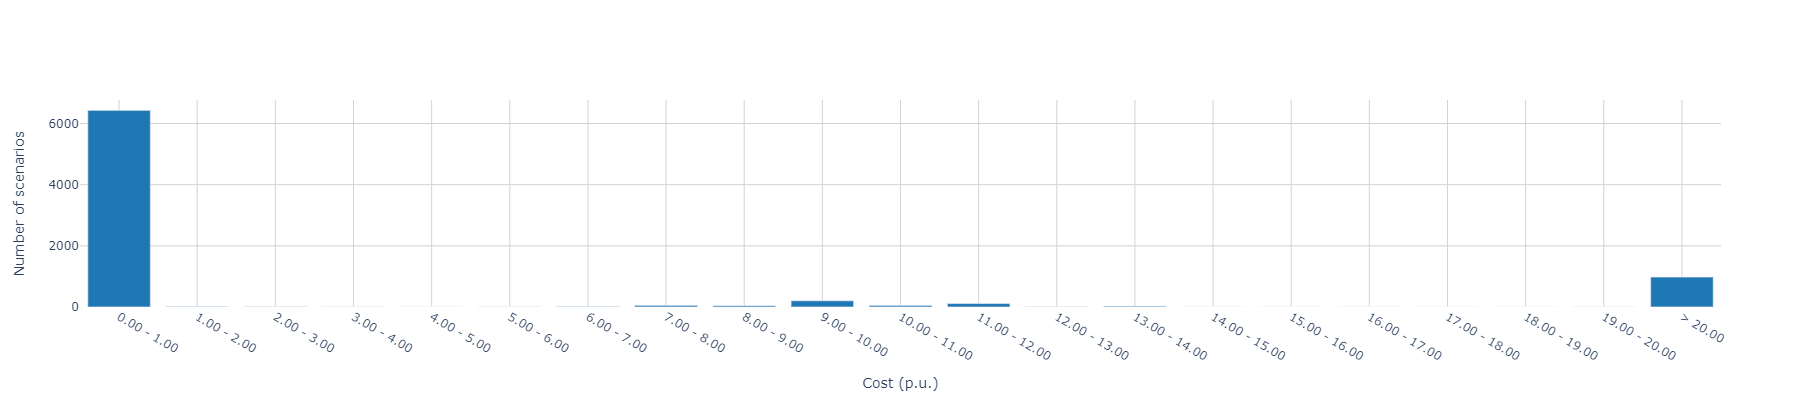

In [8]:
df = pd.read_csv(r'./data/tot_cost_failure_scenarios_240222.csv')

def plot_bar_with_outliers(series, name, end):
    start = int(series.min())
    size = 1

    # Making a histogram
    largest_value = series.max()
    if largest_value > end:
        hist = np.histogram(series, bins=np.concatenate([np.arange(start, end, 1), np.array([largest_value])], axis=None))
    else:
        hist = np.histogram(series, bins=np.concatenate([np.arange(start, end, 1), np.array([end])], axis=None))

    # Adding labels to the chart
    labels = []
    for i, j in zip(hist[1][0::1], hist[1][1::1]):
        if j <= end:
            labels.append('{:.2f} - {:.2f}'.format(i, j))
        else:
            labels.append('> {:.2f}'.format(i))

    # Plotting the graph
    data = [go.Bar(x=labels,
                   y=hist[0])]

    layout = go.Layout(
        xaxis = dict(
          title = name,
          gridcolor='lightgrey'),
        yaxis = dict(
          title = 'count',
          gridcolor='lightgrey'), 
        paper_bgcolor='rgba(0,0,0,0)',
        plot_bgcolor='rgba(0,0,0,0)'
    )
    fig = go.Figure(data=data, layout=layout)
    fig.update_traces(marker_color='#1F77B4')
    fig.update_layout(
    yaxis_title='Number of scenarios',
    width=800, height=400
)
    fig.show()

    #iplot(fig, filename='basic histogram')


plot_bar_with_outliers(df['Correction cost'], 'Cost (p.u.)', end=21)

## Klassifisering

In [9]:
df_h = pd.read_csv('results/results_classification_070322_threshold_10.csv')
df_l = pd.read_csv('results/results_classification_070322_threshold_1,13.csv')

### Precision-recall kurver

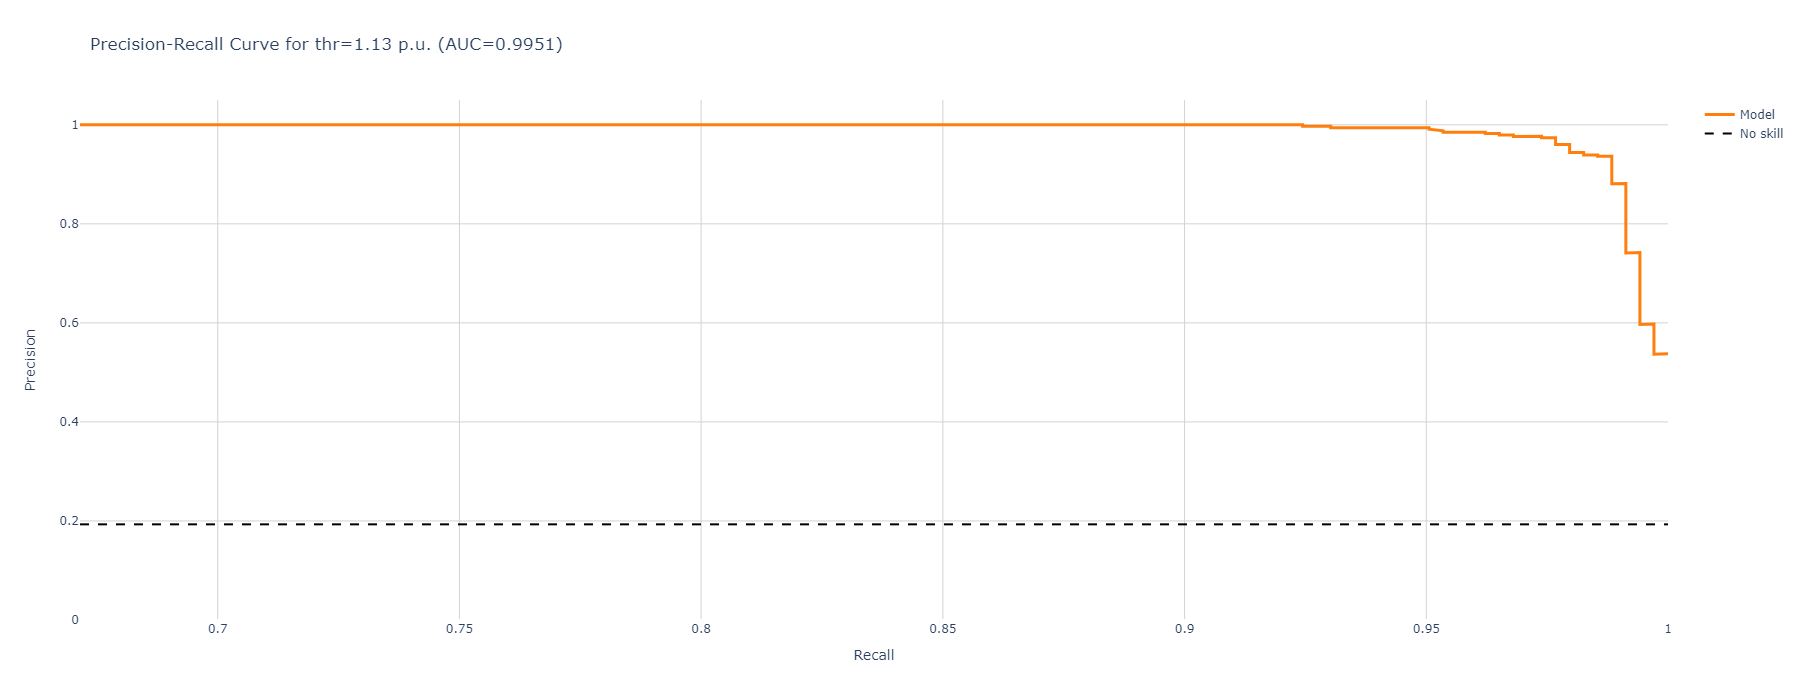

In [12]:
precision, recall, thresholds = precision_recall_curve(df_l['target'], df_l['prob'])

df_ = pd.DataFrame(data={"precision": precision[:-1], "recall": recall[:-1], "thresh":thresholds})

layout = go.Layout(
    title = f'Precision-Recall Curve for thr=1.13 p.u. (AUC={auc(recall, precision):.4f})',
    xaxis = dict(
        gridcolor='lightgrey'),
    yaxis = dict(
        gridcolor='lightgrey'), 
    paper_bgcolor='rgba(0,0,0,0)',
    plot_bgcolor='rgba(0,0,0,0)'
)

fig = go.Figure(layout=layout)

fig.add_trace(go.Scatter(x=df_['recall'], y=df_['precision'], mode='lines', line=dict(color='#FF7F0E', width=3), name="Model",))

fig.add_trace(go.Scatter(x=[recall[-2], 1], y=[df_h['Class'].sum()/df_h.shape[0], df_h['Class'].sum()/df_h.shape[0]], 
                         line_width=2, line_dash="dash", mode='lines', line_color="black", name="No skill"))

fig.update_layout(
    xaxis_title='Recall',
    yaxis_title='Precision',
    yaxis=dict(scaleanchor="y", constrain='domain', range=[0,1.05]),
    xaxis=dict(constrain='domain', scaleratio=1, range=[recall[:-1].min(), precision[:-1].max()]),
    width=500, height=700
)
fig.show()

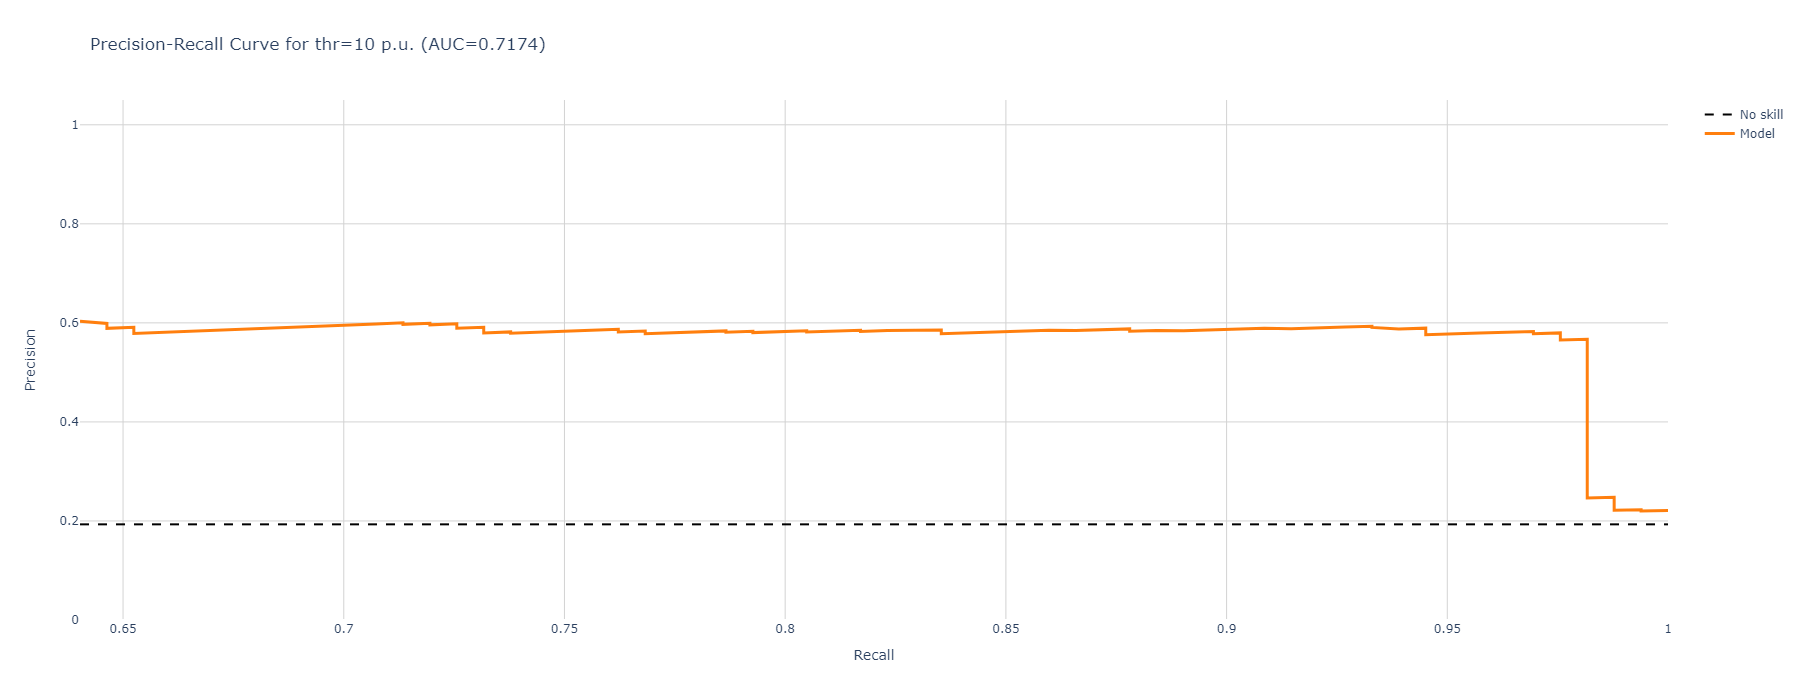

In [13]:
precision, recall, thresholds = precision_recall_curve(df_h['target'], df_h['prob'])

df_ = pd.DataFrame(data={"precision": precision[:-1], "recall": recall[:-1], "thresh":thresholds})

layout = go.Layout(
    title = f'Precision-Recall Curve for thr=10 p.u. (AUC={auc(recall, precision):.4f})',
    xaxis = dict(
        gridcolor='lightgrey'),
    yaxis = dict(
        gridcolor='lightgrey'), 
    paper_bgcolor='rgba(0,0,0,0)',
    plot_bgcolor='rgba(0,0,0,0)'
)

fig = go.Figure(layout=layout)
#fig.add_shape(
#    type='line', line=dict(dash='dash'),
#    x0=recall[:-1].min(), x1=1, y0=df['pred_f2'].sum()/df.shape[0], y1=df['pred_f2'].sum()/df.shape[0], name= "Baseline", annotation_text="Jan 1, 2018 baseline"
#)

fig.add_trace(go.Scatter(x=[recall[-2], 1], y=[df_h['Class'].sum()/df_h.shape[0], df_h['Class'].sum()/df_h.shape[0]], 
                         line_width=2, line_dash="dash", mode='lines', line_color="black", name="No skill"))

fig.add_trace(go.Scatter(x=df_['recall'], y=df_['precision'], mode='lines', line=dict(color='#FF7F0E', width=3), name="Model",))

fig.update_layout(
    xaxis_title='Recall',
    yaxis_title='Precision',
    yaxis=dict(scaleanchor="y", constrain='domain', range=[0,1.05]),
    xaxis=dict(constrain='domain', scaleratio=1, range=[recall[:-1].min(), 1]),
    width=500, height=700
)
fig.show()

### Confusion matrix

In [14]:
#Move to own file
def make_confusion_matrix(cf,
                          group_names=None,
                          categories='auto',
                          count=True,
                          percent=True,
                          cbar=True,
                          xyticks=True,
                          xyplotlabels=True,
                          sum_stats=True,
                          figsize=None,
                          cmap='Blues',
                          title=None):
    '''
    This function will make a pretty plot of an sklearn Confusion Matrix cm using a Seaborn heatmap visualization.
    Arguments
    ---------
    cf:            confusion matrix to be passed in
    group_names:   List of strings that represent the labels row by row to be shown in each square.
    categories:    List of strings containing the categories to be displayed on the x,y axis. Default is 'auto'
    count:         If True, show the raw number in the confusion matrix. Default is True.
    normalize:     If True, show the proportions for each category. Default is True.
    cbar:          If True, show the color bar. The cbar values are based off the values in the confusion matrix.
                   Default is True.
    xyticks:       If True, show x and y ticks. Default is True.
    xyplotlabels:  If True, show 'True Label' and 'Predicted Label' on the figure. Default is True.
    sum_stats:     If True, display summary statistics below the figure. Default is True.
    figsize:       Tuple representing the figure size. Default will be the matplotlib rcParams value.
    cmap:          Colormap of the values displayed from matplotlib.pyplot.cm. Default is 'Blues'
                   See http://matplotlib.org/examples/color/colormaps_reference.html
                   
    title:         Title for the heatmap. Default is None.
    '''


    # CODE TO GENERATE TEXT INSIDE EACH SQUARE
    blanks = ['' for i in range(cf.size)]

    if group_names and len(group_names)==cf.size:
        group_labels = ["{}\n".format(value) for value in group_names]
    else:
        group_labels = blanks

    if count:
        group_counts = ["{0:0.0f}\n".format(value) for value in cf.flatten()]
    else:
        group_counts = blanks

    if percent:
        group_percentages = ["{0:.2%}".format(value) for value in cf.flatten()/np.sum(cf)]
    else:
        group_percentages = blanks

    box_labels = [f"{v1}{v2}{v3}".strip() for v1, v2, v3 in zip(group_labels,group_counts,group_percentages)]
    box_labels = np.asarray(box_labels).reshape(cf.shape[0],cf.shape[1])


    # CODE TO GENERATE SUMMARY STATISTICS & TEXT FOR SUMMARY STATS
    if sum_stats:
        #Accuracy is sum of diagonal divided by total observations
        accuracy  = np.trace(cf) / float(np.sum(cf))

        #if it is a binary confusion matrix, show some more stats
        if len(cf)==2:
            #Metrics for Binary Confusion Matrices
            precision = cf[1,1] / sum(cf[:,1])
            recall    = cf[1,1] / sum(cf[1,:])
            f1_score  = 2*precision*recall / (precision + recall)
            stats_text = "\n\nAccuracy={:0.3f}\nPrecision={:0.3f}\nRecall={:0.3f}".format(
                accuracy,precision,recall,f1_score)
        else:
            stats_text = "\n\nAccuracy={:0.3f}".format(accuracy)
    else:
        stats_text = ""


    # SET FIGURE PARAMETERS ACCORDING TO OTHER ARGUMENTS
    if figsize==None:
        #Get default figure size if not set
        figsize = plt.rcParams.get('figure.figsize')

    if xyticks==False:
        #Do not show categories if xyticks is False
        categories=False


    # MAKE THE HEATMAP VISUALIZATION
    plt.figure(figsize=figsize)
    sns.heatmap(cf,annot=box_labels, annot_kws={"size":14},fmt="",cmap=cmap,cbar=cbar,xticklabels=categories,yticklabels=categories)

    if xyplotlabels:
        plt.ylabel('True label')
        plt.xlabel('Predicted label' + stats_text)
    else:
        plt.xlabel(stats_text)
    
    if title:
        plt.title(title)

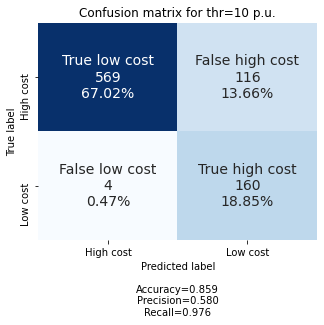

In [15]:
cf_matrix = confusion_matrix(df_h['target'], df_h['pred_f2'])

labels = ['True low cost','False high cost','False low cost','True high cost']
categories = ['High cost', 'Low cost']
make_confusion_matrix(cf_matrix, 
                      group_names=labels,
                      categories=categories, 
                      cmap='Blues',
                      title='Confusion matrix for thr=10 p.u.',
                      cbar=False,
                      figsize=(5, 4))

#plt.savefig("cf_10.png")

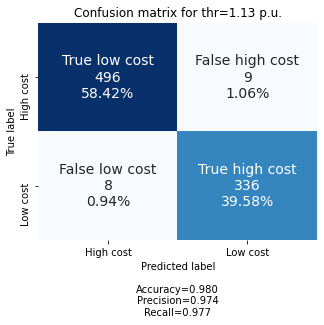

In [16]:
cf_matrix = confusion_matrix(df_l['target'], df_l['pred_f2'])

labels = ['True low cost','False high cost','False low cost','True high cost']
categories = ['High cost', 'Low cost']
make_confusion_matrix(cf_matrix, 
                      group_names=labels,
                      categories=categories, 
                      cmap='Blues',
                      title='Confusion matrix for thr=1.13 p.u.',
                      cbar=False,
                      figsize=(5, 4))
#plt.savefig("cf_1,13.png")

## Regresjon 1 dim

In [57]:
df_rl = pd.read_csv(r'./results/results_regression_080322_1dim_threshold_1,13_setmax_1,13.csv')
df_rh = pd.read_csv(r'./results/results_regression_080322_1dim_threshold_10_setmax_10.csv')

In [58]:
df_rl['d_acc'] = (df_rl['pred'] - df_rl['target'])**2

In [59]:
(df_rl['d_acc'].mean())**0.5/df_rl['target'].mean()

0.733847281741383

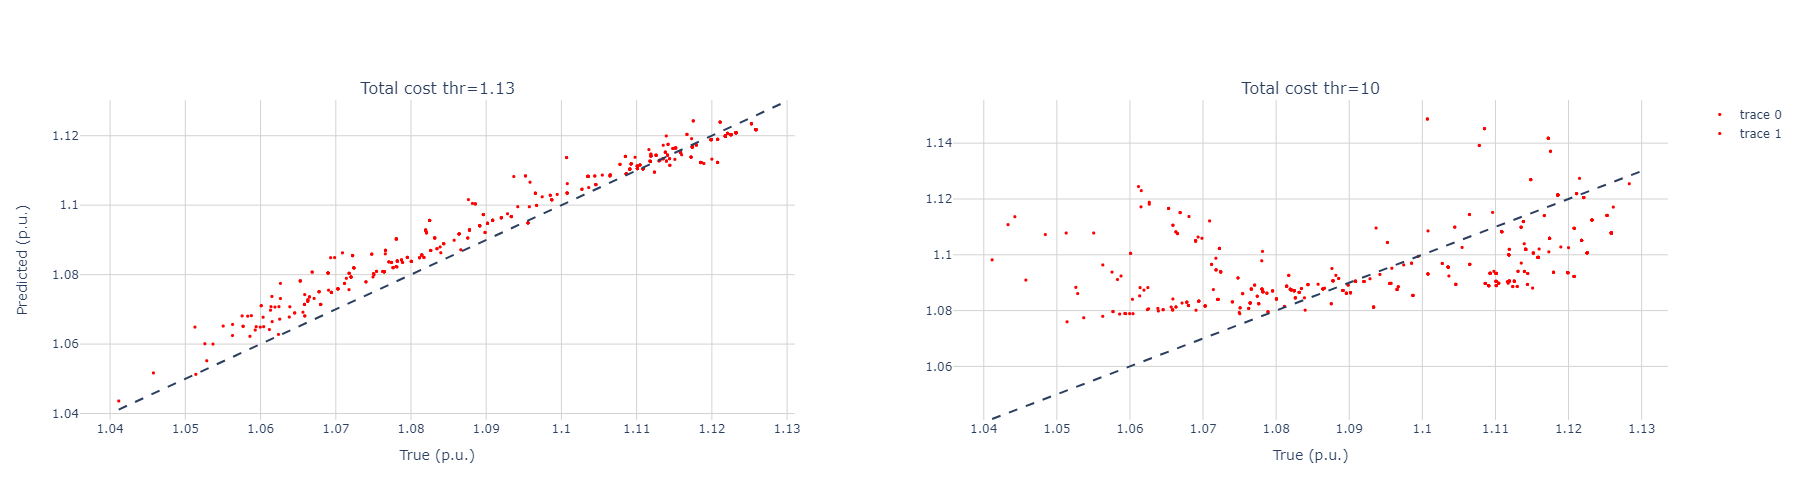

In [18]:
from plotly.subplots import make_subplots

max_ = 1.13

plot_dfl = df_rl[df_rl['target']<max_].copy()
plot_dfh = df_rh[df_rh['target']<max_].copy()

fig = make_subplots(rows=1, cols=2, subplot_titles=("Total cost thr=1.13", "Total cost thr=10"))

fig.add_scatter(x=plot_dfl['target'], y=plot_dfl['pred'], mode='markers', marker=dict(color='red', size=3), row=1, col=1)

fig.add_shape(
    type='line', line=dict(dash='dash'),
    x0=plot_dfl['target'].min(), x1=max_, y0=plot_dfl['target'].min(), y1=max_, name= "Baseline", row=1, col=1
)

fig.add_scatter(x=plot_dfh['target'], y=plot_dfh['pred'], mode='markers', marker=dict(color='red', size=3), row=1, col=2)

fig.add_shape(
    type='line', line=dict(dash='dash'),
    x0=plot_dfh['target'].min(), x1=max_, y0=plot_dfh['target'].min(), y1=max_, name= "Baseline", row=1, col=2
)

fig.update_xaxes(gridcolor='lightgrey', title='True (p.u.)')
fig.update_yaxes(gridcolor='lightgrey')

fig.update_layout(
    paper_bgcolor='rgba(0,0,0,0)',
    plot_bgcolor='rgba(0,0,0,0)',
    width=700, height=500,
    yaxis_title='Predicted (p.u.)'
)
fig.show()

### Regn ut forventet kostnad

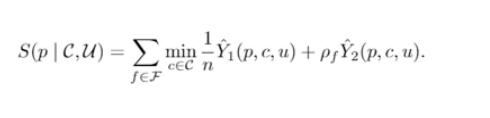

In [25]:
#Keep lowest cost per given prv and fault
df_rh["prev_id,fault"] = df_rh[['prev_id', 'fault']].agg('-'.join, axis=1)
df_rl["prev_id,fault"] = df_rl[['prev_id', 'fault']].agg('-'.join, axis=1)

df_rh = df_rl.copy()

# First find out how many failure scenarios per prev has in dataset
# If one or more failure scenarios missing from preventive strategy, do not calculate expected cost

agg = {
    'fault': list,
    'corr': list,
}

df_fault = df_rh.groupby("prev_id").agg(agg)
df_fault["fault unique"] = df_fault["fault"].apply(lambda row: list(dict.fromkeys(row)))
df_fault.head()

,fault,corr,fault unique
prev_id,,,
p1000,"[fault_L10, fault_L11, fault_L18, fault_L19]","[fault, fault, fault, fault]","[fault_L10, fault_L11, fault_L18, fault_L19]"
p1035,"[fault_L10, fault_L11, fault_L18, fault_L19]","[fault, fault, fault, fault]","[fault_L10, fault_L11, fault_L18, fault_L19]"
p1041,"[fault_L10, fault_L11, fault_L18, fault_L19]","[fault, fault, fault, fault]","[fault_L10, fault_L11, fault_L18, fault_L19]"
p1042,"[fault_L10, fault_L11, fault_L18, fault_L19]","[fault, fault, fault, fault]","[fault_L10, fault_L11, fault_L18, fault_L19]"
p1050,"[fault_L10, fault_L11, fault_L18, fault_L19]","[fault, fault, fault, fault]","[fault_L10, fault_L11, fault_L18, fault_L19]"


In [26]:
def num_failure_missing(row):
    return 4 - len(row["fault"])

df_fault["num fault missing"] = df_fault["fault unique"].apply(lambda row: 4 - len(row))

df_fault[df_fault["num fault missing"] != 0].head()

,fault,corr,fault unique,num fault missing
prev_id,,,,
p108,"[fault_L18, fault_L19]","[fault, fault]","[fault_L18, fault_L19]",2
p1206,"[fault_L18, fault_L19]","[fault, fault]","[fault_L18, fault_L19]",2
p1231,"[fault_L18, fault_L19]","[fault, fault]","[fault_L18, fault_L19]",2
p1390,"[fault_L18, fault_L19]","[fault, fault]","[fault_L18, fault_L19]",2
p238,[fault_L19],[fault],[fault_L19],3


In [27]:
df_rh.set_index('prev_id', inplace=True)

#adding column to main dataframe
df_rh = df_rh.join(df_fault[['num fault missing']])

In [28]:
# Sort values in ascending order so value kept is corrective measure with lowest cost
df_sort = df_rh.sort_values(['prev_id,fault', 'Total cost'])
df_d = df_sort.drop_duplicates('prev_id,fault',keep='first')
df_d

,Line10,Line11,Line18,Line19,Area1_prod,Area2_prod,Area3_prod,Area1_load,Area2_load,Area3_load,...,Area2-fault2,Area3-fault2,inter_area_flow_scaled,Area1_prod_scaled,Area2_prod_scaled,Area3_prod_scaled,target,pred,"prev_id,fault",num fault missing
prev_id,,,,,,,,,,,,,,,,,,,,,
p1000,1.349568,111.457467,80.106552,-71.645913,345.740522,252.900003,504.986755,129.41124,102.497107,768.196686,...,0,0,0.323482,0.490235,0.299533,0.817341,1.083154,1.090562,p1000-fault_L10,0
p1000,1.349568,111.457467,80.106552,-71.645913,345.740522,252.900003,504.986755,129.41124,102.497107,768.196686,...,0,0,0.323482,0.490235,0.299533,0.817341,1.113823,1.115251,p1000-fault_L11,0
p1000,1.349568,111.457467,80.106552,-71.645913,345.740522,252.900003,504.986755,129.41124,102.497107,768.196686,...,0,0,0.323482,0.490235,0.299533,0.817341,1.095559,1.094894,p1000-fault_L18,0
p1000,1.349568,111.457467,80.106552,-71.645913,345.740522,252.900003,504.986755,129.41124,102.497107,768.196686,...,1,1,0.323482,0.490235,0.299533,0.817341,1.093334,1.096716,p1000-fault_L19,0
p1035,43.065264,131.722460,70.927479,-63.584629,407.721211,193.943950,501.962118,129.41124,102.497107,768.196686,...,0,0,0.415383,0.617549,0.178432,0.811128,1.071782,1.080371,p1035-fault_L10,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
p981,-12.408324,70.927479,60.794982,-52.911359,291.452642,228.611771,583.562866,129.41124,102.497107,768.196686,...,1,1,0.184796,0.378723,0.249642,0.978743,1.113511,1.113382,p981-fault_L19,0
p987,33.072612,151.987454,89.345568,-81.059976,417.993553,239.830039,445.803688,129.41124,102.497107,768.196686,...,0,0,0.510211,0.638649,0.272686,0.695774,1.061547,1.066464,p987-fault_L10,0
p987,33.072612,151.987454,89.345568,-81.059976,417.993553,239.830039,445.803688,129.41124,102.497107,768.196686,...,0,0,0.510211,0.638649,0.272686,0.695774,1.119998,1.113257,p987-fault_L11,0


In [31]:
# Per scenario: mean dispatch cost and sum correction costs

aggregations = {
    'inter_area_flow': 'mean',
    'Line11': 'mean',
    'fault': list,
    'corr': list,
    'Total cost': 'mean',
    'pred': 'mean',
    'CENS': 'mean',
    'num fault missing': 'mean'
}

# Use formula given earlier to find cost per preventive strategy

failure_rate = 0.1

df_prev = df_d.groupby("prev_id").agg(aggregations)

In [32]:
df_prev.head()

,inter_area_flow,Line11,fault,corr,Total cost,pred,CENS,num fault missing
prev_id,,,,,,,,
p1000,264.559500,111.457467,"[fault_L10, fault_L11, fault_L18, fault_L19]","[fault, fault, fault, fault]",1.096467,1.099356,0.0,0
p1035,309.299832,131.722460,"[fault_L10, fault_L11, fault_L18, fault_L19]","[fault, fault, fault, fault]",1.084756,1.089627,0.0,0
p1041,264.085383,111.457467,"[fault_L10, fault_L11, fault_L18, fault_L19]","[fault, fault, fault, fault]",1.094210,1.099396,0.0,0
p1042,263.562021,111.457467,"[fault_L10, fault_L11, fault_L18, fault_L19]","[fault, fault, fault, fault]",1.091687,1.097857,0.0,0
p1050,195.368379,81.059977,"[fault_L10, fault_L11, fault_L18, fault_L19]","[fault, fault, fault, fault]",1.108115,1.114540,0.0,0


In [33]:
# Find prev ids that have one or more scenarios with CENS or saved by SPS

df_prev["corr_unique"] = df_prev["corr"].apply(lambda x: list(dict.fromkeys(x)))


def classify_prev(row):
    if row["CENS"] > 0:
        return "Not N-1 safe"
    else:
        if len(row["corr_unique"])==1 and row["corr_unique"][0] == 'fault':
            return "N-1 safe"
        else:
            return "Saved by SPS"

df_prev["corr3"] = df_prev.apply(classify_prev, axis=1)  

In [34]:
df_prev[df_prev["corr3"] != "N-1 safe"]

,inter_area_flow,Line11,fault,corr,Total cost,pred,CENS,num fault missing,corr_unique,corr3
prev_id,,,,,,,,,,
p1394,339.260615,152.878043,"[fault_L10, fault_L11, fault_L18, fault_L19]","[fault, fault, fault, fault]",7.528119,1.085137,6.464389,0,[fault],Not N-1 safe
p822,357.906876,161.954659,"[fault_L10, fault_L11, fault_L18, fault_L19]","[fault, fault, fault, fault]",2.578957,1.084527,1.491837,0,[fault],Not N-1 safe
p914,356.363088,159.702393,"[fault_L11, fault_L18, fault_L19]","[fault, fault, fault]",4.170469,1.082004,3.073013,1,[fault],Not N-1 safe


In [35]:
df_prev[df_prev["num fault missing"] != 0].head()

,inter_area_flow,Line11,fault,corr,Total cost,pred,CENS,num fault missing,corr_unique,corr3
prev_id,,,,,,,,,,
p108,377.121505,162.119951,"[fault_L18, fault_L19]","[fault, fault]",1.060939,1.067777,0.0,2,[fault],N-1 safe
p1206,399.205367,172.252448,"[fault_L18, fault_L19]","[fault, fault]",1.052125,1.053240,0.0,2,[fault],N-1 safe
p1231,376.929580,162.119951,"[fault_L18, fault_L19]","[fault, fault]",1.059467,1.064979,0.0,2,[fault],N-1 safe
p1390,375.009349,168.779009,"[fault_L18, fault_L19]","[fault, fault]",1.060407,1.067896,0.0,2,[fault],N-1 safe
p238,466.094860,202.649939,[fault_L19],[fault],1.228667,1.067470,0.0,3,[fault],N-1 safe


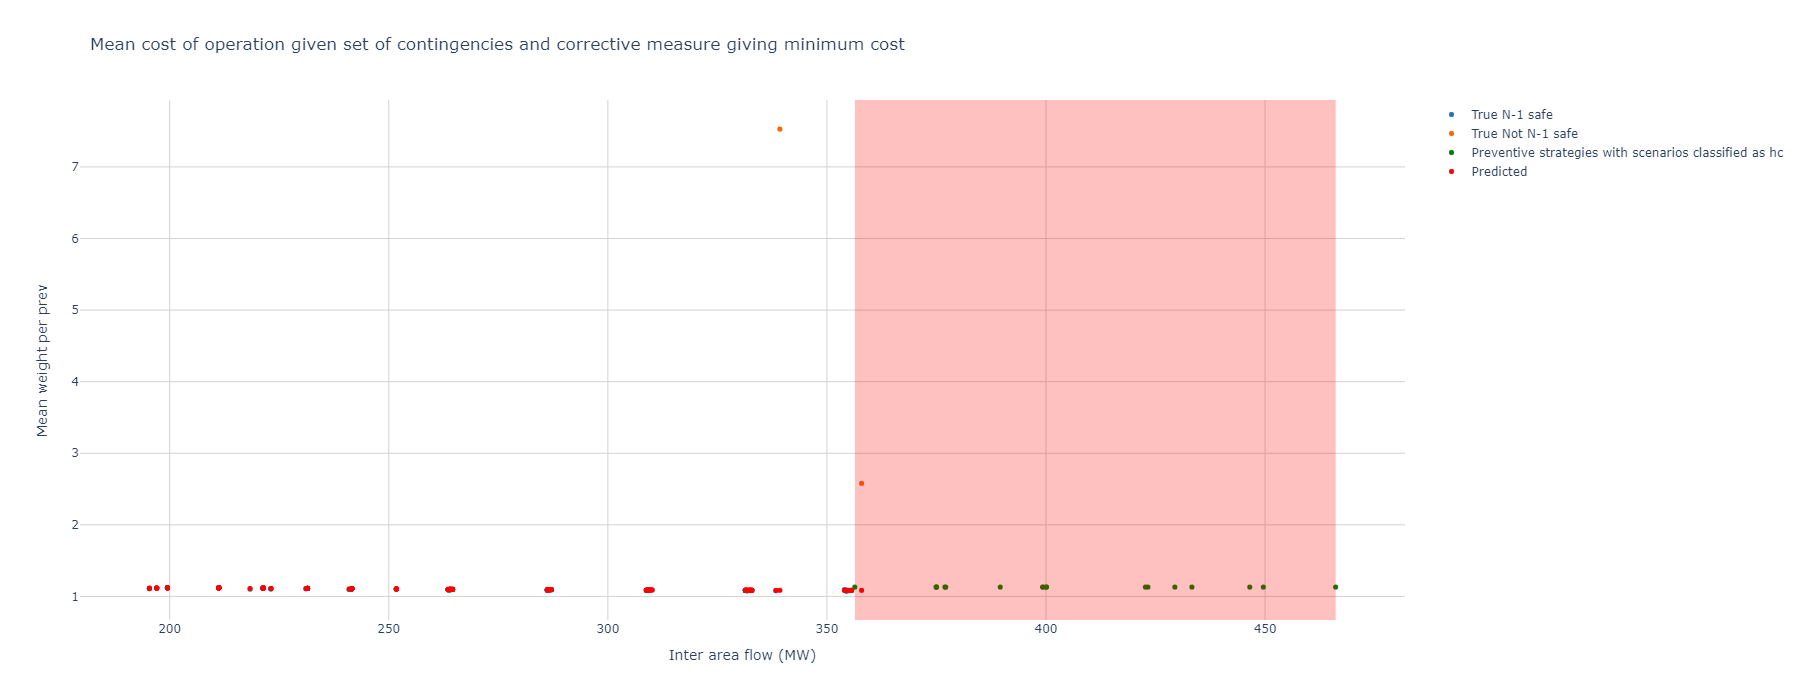

In [36]:
plot_df = df_prev[df_prev["num fault missing"] == 0].copy()
plot_df2 = df_prev[df_prev["num fault missing"] != 0].copy()

plot_df2['Total cost'] = max_

layout = go.Layout(
    title = 'Mean cost of operation given set of contingencies and corrective measure giving minimum cost',
    xaxis = dict(
        gridcolor='lightgrey'),
    yaxis = dict(
        gridcolor='lightgrey'), 
    paper_bgcolor='rgba(0,0,0,0)',
    plot_bgcolor='rgba(0,0,0,0)'
)

fig = go.Figure(layout=layout)

groups = ["N-1 safe", "Saved by SPS", "Not N-1 safe"]

colors = ["#1F77B4","#FFDA00", "#FF6600"]

for index, group in enumerate(groups):
    new_df = plot_df[plot_df['corr3'] == group]
    fig.add_trace(go.Scatter(x=new_df["inter_area_flow"], y=new_df['Total cost'], marker=dict(color=colors[index], size=5), mode='markers', name='True {}'.format(group), hovertemplate = ('Prev id: ' + new_df.index)))


fig.add_trace(go.Scatter(x=plot_df2["inter_area_flow"], y=plot_df2['Total cost'], mode='markers', marker=dict(color='green', size=5), name="Preventive strategies with scenarios classified as hc", hovertemplate = ('Prev id: ' + plot_df2.index)))

fig.add_trace(go.Scatter(x=plot_df["inter_area_flow"], y=plot_df['pred'], mode='markers', marker=dict(color='red', size=5), name="Predicted", hovertemplate = ('Prev id: ' + df_prev.index)))

fig.add_vrect(x0=plot_df2["inter_area_flow"].min(), x1=plot_df2["inter_area_flow"].max(), fillcolor="red", opacity=0.25, line_width=0)

fig.update_layout(
    xaxis_title='Inter area flow (MW)',
    yaxis_title='Mean weight per prev',
    width=1200, height=700
)
fig.show()

## Regression 2-dim

In [70]:
df_rl = pd.read_csv(r'./results/results_regression_080322_threshold_1,13.csv')
df_rh = pd.read_csv(r'./results/results_regression_080322_threshold_10.csv')

In [62]:
df_rl['d_acc'] = (df_rl['Dispatch_cost_target'] - df_rl['Dispatch_cost_pred'])**2
df_rl['c_acc'] = (df_rl['Correction_cost_target'] - df_rl['Correction_cost_pred'])**2

nrmse_d = (df_rl['d_acc'].mean())**0.5/df_rl['Dispatch_cost_target'].mean()
nrmse_c = (df_rl['c_acc'].mean())*0.5/df_rl['Correction_cost_target'].mean()
100*(nrmse_d + nrmse_c)/2

8.24387092063326

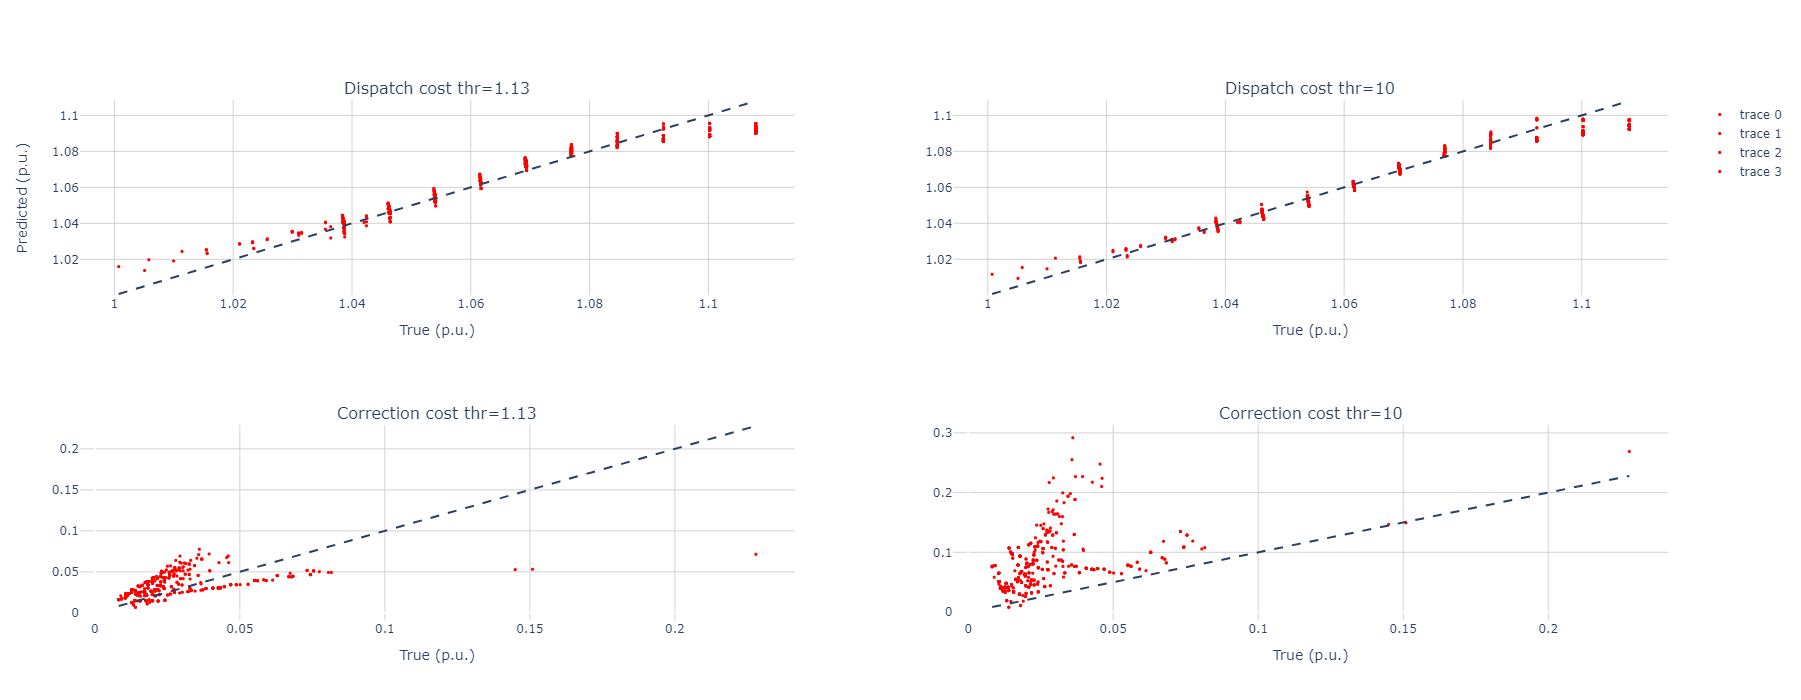

In [63]:
max_ = 1.13

plot_dfl = df_rl[df_rl['Correction_cost_target']<max_].copy()
plot_dfh = df_rh[df_rh['Correction_cost_target']<max_].copy()

fig = make_subplots(rows=2, cols=2, subplot_titles=("Dispatch cost thr=1.13", "Dispatch cost thr=10", "Correction cost thr=1.13", "Correction cost thr=10"))

# Add scatters

fig.add_scatter(x=plot_dfl['Dispatch_cost_target'], y=plot_dfl['Dispatch_cost_pred'], mode='markers', marker=dict(color='red', size=3), row=1, col=1)
fig.add_scatter(x=plot_dfl['Correction_cost_target'], y=plot_dfl['Correction_cost_pred'], mode='markers', marker=dict(color='red', size=3), row=2, col=1)


fig.add_scatter(x=plot_dfh['Dispatch_cost_target'], y=plot_dfh['Dispatch_cost_pred'], mode='markers', marker=dict(color='red', size=3), row=1, col=2)
fig.add_scatter(x=plot_dfh['Correction_cost_target'], y=plot_dfh['Correction_cost_pred'], mode='markers', marker=dict(color='red', size=3), row=2, col=2)



fig.add_shape(
    type='line', line=dict(dash='dash'),
    x0=plot_dfl['Dispatch_cost_target'].min(), x1=plot_dfl['Dispatch_cost_target'].max(), y0=plot_dfl['Dispatch_cost_target'].min(), y1=plot_dfl['Dispatch_cost_target'].max(), name= "Baseline", row=1, col=1
)

fig.add_shape(
    type='line', line=dict(dash='dash'),
    x0=plot_dfl['Correction_cost_target'].min(), x1=plot_dfl['Correction_cost_target'].max(), y0=plot_dfl['Correction_cost_target'].min(), y1=plot_dfl['Correction_cost_target'].max(), name= "Baseline", row=2, col=1
)

fig.add_shape(
    type='line', line=dict(dash='dash'),
    x0=plot_dfh['Dispatch_cost_target'].min(), x1=plot_dfh['Dispatch_cost_target'].max(), y0=plot_dfh['Dispatch_cost_target'].min(), y1=plot_dfh['Dispatch_cost_target'].max(), name= "Baseline", row=1, col=2
)

fig.add_shape(
    type='line', line=dict(dash='dash'),
    x0=plot_dfh['Correction_cost_target'].min(), x1=plot_dfh['Correction_cost_target'].max(), y0=plot_dfh['Correction_cost_target'].min(), y1=plot_dfh['Correction_cost_target'].max(), name= "Baseline", row=2, col=2
)

fig.update_xaxes(gridcolor='lightgrey', title='True (p.u.)')
fig.update_yaxes(gridcolor='lightgrey')

fig.update_layout(
    paper_bgcolor='rgba(0,0,0,0)',
    plot_bgcolor='rgba(0,0,0,0)',
    width=700, height=700, 
    yaxis_title='Predicted (p.u.)'
)
fig.show()

### Regn ut forventet kostnad

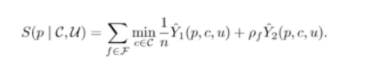

In [71]:
#Keep lowest cost per given prv and fault
df_rh["prev_id,fault"] = df_rh[['prev_id', 'fault']].agg('-'.join, axis=1)
df_rl["prev_id,fault"] = df_rl[['prev_id', 'fault']].agg('-'.join, axis=1)

# To make plot for low cost and set max_ to be threshold value
df_rh = df_rl.copy()
max_ = 1.13

# First find out how many failure scenarios per prev has in dataset

agg = {
    'fault': list,
    'corr': list,
}

df_fault = df_rh.groupby("prev_id").agg(agg)
df_fault["fault unique"] = df_fault["fault"].apply(lambda row: list(dict.fromkeys(row)))
df_fault.head()

,fault,corr,fault unique
prev_id,,,
p1000,"[fault_L10, fault_L11, fault_L18, fault_L19]","[fault, fault, fault, fault]","[fault_L10, fault_L11, fault_L18, fault_L19]"
p1035,"[fault_L10, fault_L11, fault_L18, fault_L19]","[fault, fault, fault, fault]","[fault_L10, fault_L11, fault_L18, fault_L19]"
p1041,"[fault_L10, fault_L11, fault_L18, fault_L19]","[fault, fault, fault, fault]","[fault_L10, fault_L11, fault_L18, fault_L19]"
p1042,"[fault_L10, fault_L11, fault_L18, fault_L19]","[fault, fault, fault, fault]","[fault_L10, fault_L11, fault_L18, fault_L19]"
p1050,"[fault_L10, fault_L11, fault_L18, fault_L19]","[fault, fault, fault, fault]","[fault_L10, fault_L11, fault_L18, fault_L19]"


In [72]:
def num_failure_missing(row):
    return 4 - len(row["fault"])

df_fault["num fault missing"] = df_fault["fault unique"].apply(lambda row: 4 - len(row))

df_fault[df_fault["num fault missing"] != 0].head()

,fault,corr,fault unique,num fault missing
prev_id,,,,
p108,"[fault_L18, fault_L19]","[fault, fault]","[fault_L18, fault_L19]",2
p1206,"[fault_L18, fault_L19]","[fault, fault]","[fault_L18, fault_L19]",2
p1231,"[fault_L18, fault_L19]","[fault, fault]","[fault_L18, fault_L19]",2
p1390,"[fault_L18, fault_L19]","[fault, fault]","[fault_L18, fault_L19]",2
p238,[fault_L19],[fault],[fault_L19],3


In [73]:
df_rh.set_index('prev_id', inplace=True)

# Add to dataframe
df_rh = df_rh.join(df_fault[['num fault missing']])

In [75]:
# Sort values in ascending order so value kept is corrective measure with lowest cost
df_sort = df_rh.sort_values(['prev_id,fault', 'Total cost'])
df_d = df_sort.drop_duplicates('prev_id,fault',keep='first')
df_d.head()

,Line10,Line11,Line18,Line19,Area1_prod,Area2_prod,Area3_prod,Area1_load,Area2_load,Area3_load,...,inter_area_flow_scaled,Area1_prod_scaled,Area2_prod_scaled,Area3_prod_scaled,Dispatch_cost_target,Correction_cost_target,Dispatch_cost_pred,Correction_cost_pred,"prev_id,fault",num fault missing
prev_id,,,,,,,,,,,,,,,,,,,,,
p1000,1.349568,111.457467,80.106552,-71.645913,345.740522,252.900003,504.986755,129.41124,102.497107,768.196686,...,0.323482,0.490235,0.299533,0.817341,1.069159,0.013995,1.076334,0.027120,p1000-fault_L10,0
p1000,1.349568,111.457467,80.106552,-71.645913,345.740522,252.900003,504.986755,129.41124,102.497107,768.196686,...,0.323482,0.490235,0.299533,0.817341,1.069159,0.044664,1.073124,0.031924,p1000-fault_L11,0
p1000,1.349568,111.457467,80.106552,-71.645913,345.740522,252.900003,504.986755,129.41124,102.497107,768.196686,...,0.323482,0.490235,0.299533,0.817341,1.069159,0.026400,1.075641,0.031880,p1000-fault_L18,0
p1000,1.349568,111.457467,80.106552,-71.645913,345.740522,252.900003,504.986755,129.41124,102.497107,768.196686,...,0.323482,0.490235,0.299533,0.817341,1.069159,0.024175,1.074439,0.015327,p1000-fault_L19,0
p1035,43.065264,131.722460,70.927479,-63.584629,407.721211,193.943950,501.962118,129.41124,102.497107,768.196686,...,0.415383,0.617549,0.178432,0.811128,1.053963,0.017818,1.056000,0.037668,p1035-fault_L10,0


In [76]:
# Per scenario: mean dispatch cost and sum correction costs

aggregations = {
    'inter_area_flow': 'mean',
    'Line11': 'mean',
    'fault': list,
    'corr': list,
    'Dispatch_cost_target': 'mean', # Mean of dispatch costs
    'Dispatch_cost_pred': 'mean',
    'Correction_cost_target': 'sum', # Sum up correction costs
    'Correction_cost_pred': 'sum',
    'CENS': 'mean',
    'num fault missing': 'mean'
}

# Use formula given earlier to find cost per preventive strategy

failure_rate = 0.1

df_prev = df_d.groupby("prev_id").agg(aggregations)
df_prev.head()

,inter_area_flow,Line11,fault,corr,Dispatch_cost_target,Dispatch_cost_pred,Correction_cost_target,Correction_cost_pred,CENS,num fault missing
prev_id,,,,,,,,,,
p1000,264.559500,111.457467,"[fault_L10, fault_L11, fault_L18, fault_L19]","[fault, fault, fault, fault]",1.069159,1.074885,0.109234,0.106251,0.0,0
p1035,309.299832,131.722460,"[fault_L10, fault_L11, fault_L18, fault_L19]","[fault, fault, fault, fault]",1.053963,1.055126,0.123169,0.151376,0.0,0
p1041,264.085383,111.457467,"[fault_L10, fault_L11, fault_L18, fault_L19]","[fault, fault, fault, fault]",1.069270,1.073695,0.099762,0.112143,0.0,0
p1042,263.562021,111.457467,"[fault_L10, fault_L11, fault_L18, fault_L19]","[fault, fault, fault, fault]",1.069392,1.071379,0.089178,0.118264,0.0,0
p1050,195.368379,81.059977,"[fault_L10, fault_L11, fault_L18, fault_L19]","[fault, fault, fault, fault]",1.092439,1.093454,0.062704,0.065615,0.0,0


In [77]:
# Find prev ids that have one or more scenarios with CENS or saved by SPS

df_prev["corr_unique"] = df_prev["corr"].apply(lambda x: list(dict.fromkeys(x)))

In [78]:
def classify_prev(row):
    if row["CENS"] > 0:
        return "Not N-1 safe"
    else:
        if len(row["corr_unique"])==1 and row["corr_unique"][0] == 'fault':
            return "N-1 safe"
        else:
            return "Saved by SPS"

df_prev["corr3"] = df_prev.apply(classify_prev, axis=1)  
df_prev[df_prev["corr3"] != "N-1 safe"]

,inter_area_flow,Line11,fault,corr,Dispatch_cost_target,Dispatch_cost_pred,Correction_cost_target,Correction_cost_pred,CENS,num fault missing,corr_unique,corr3
prev_id,,,,,,,,,,,,
p1394,339.260615,152.878043,"[fault_L10, fault_L11, fault_L18, fault_L19]","[fault, fault, fault, fault]",1.042014,1.041520,3.417305,0.191962,6.464389,0,[fault],Not N-1 safe
p822,357.906876,161.954659,"[fault_L10, fault_L11, fault_L18, fault_L19]","[fault, fault, fault, fault]",1.035534,1.038073,1.215807,0.203530,1.491837,0,[fault],Not N-1 safe
p914,356.363088,159.702393,"[fault_L11, fault_L18, fault_L19]","[fault, fault, fault]",1.036421,1.036214,1.307043,0.159871,3.073013,1,[fault],Not N-1 safe


In [79]:
#Calculate total expected cost given failure_rate
df_prev["total_cost_target"] =  df_prev["Dispatch_cost_target"] + failure_rate*df_prev["Correction_cost_target"]
df_prev["total_cost_pred"] =  df_prev["Dispatch_cost_pred"] + failure_rate*df_prev["Correction_cost_pred"]

In [279]:
# Assume Total cost higher than threshold in scenarios
plot_df3["Line11"].min()

162.1199512937369

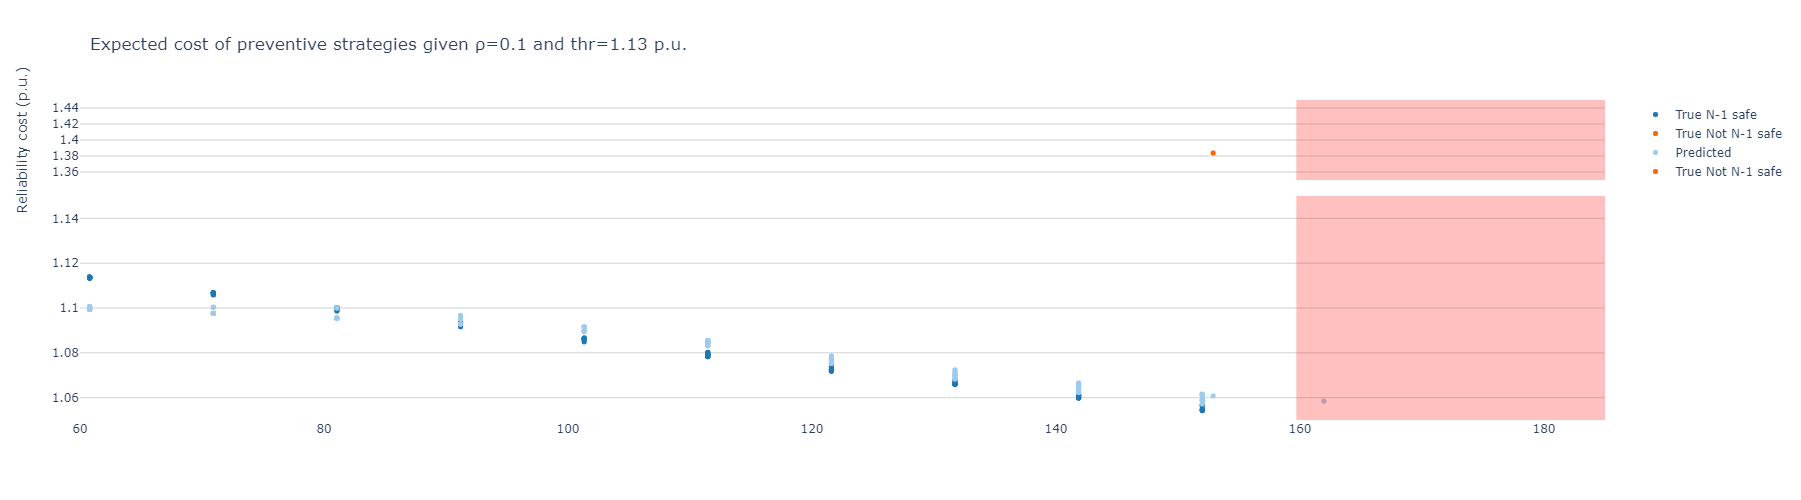

In [84]:
from plotly.subplots import make_subplots

# colors and cut-offs

cut_interval = [1.15, 1.35]

# subplot setup
fig = make_subplots(rows=2, cols=1, vertical_spacing = 0.04)
fig.update_layout(title = 'Expected cost of preventive strategies given ρ={} and thr={} p.u.'.format(failure_rate, max_))


# Make df for high cost

plot_df4 = df_prev[df_prev["total_cost_target"] > 1.2].copy()

plot_df5 = plot_df[plot_df["total_cost_target"] < 1.2].copy()

for index, group in enumerate(groups):
    new_df = plot_df5[plot_df5['corr3'] == group]
    fig.add_trace(go.Scatter(x=new_df["Line11"], y=new_df['total_cost_target'], marker=dict(color=colors[index], size=5), mode='markers', name='True {}'.format(group), hovertemplate = ('Prev id: ' + new_df.index)), row=2, col=1)


fig.add_trace(go.Scatter(x=plot_df["Line11"], y=plot_df['total_cost_pred'], mode='markers', marker=dict(color='#9ecbed', size=5), name="Predicted", hovertemplate = ('Prev id :' + plot_df.index)), row=2, col=1)

    
fig.add_trace(go.Scatter(x=plot_df4["Line11"], y=plot_df4['total_cost_target'], mode='markers', marker=dict(color=colors[2], size=5), name="True Not N-1 safe", hovertemplate = ('Prev id: ' + plot_df4.index)), row=1, col=1)


# Create own dataframe for prev_ids without all failure scenarios

plot_df_high = df_prev[df_prev["num fault missing"] > 0].copy()

plot_df_high['total_cost_target'] = 1.4

#fig.add_trace(go.Scatter(x=plot_df_high["Line11"], y=plot_df_high['total_cost_target'], mode='markers', marker=dict(color='#6a6a6a', size=5), name="1 or more contingency scenarios classified as high cost", hovertemplate = ('Prev id: ' + plot_df_high.index)))

# Add shaded area

fig.add_vrect(x0=plot_df_high["Line11"].min(), x1=plot_df_high["Line11"].max(), fillcolor="red", opacity=0.25, line_width=0)



# Some aesthetical adjustments to layout
fig.update_yaxes(range=[1.05, cut_interval[0]], row=2, col=1, gridcolor='lightgrey')
fig.update_yaxes(range=[cut_interval[1], 1.45], row=1, col=1, gridcolor='lightgrey')
fig.update_xaxes(range=[60, 185], visible=True, row=2, col=1)#, gridcolor='lightgrey')
fig.update_xaxes(range=[60, 185], visible=False, row=1, col=1)#, gridcolor='lightgrey')
fig['layout']['yaxis1'].update(domain=[0.75, 1])
fig['layout']['yaxis2'].update(domain=[0, 0.7])

fig.update_layout(
    paper_bgcolor='rgba(0,0,0,0)',
    plot_bgcolor='rgba(0,0,0,0)',
    xaxis_title='Power Flow Line 11 (MW)',
    yaxis_title='Reliability cost (p.u.)',
    width=700, height=500
)

fig.show()